In [1]:
TrainData_name = 'Mawqif_AllTargets_Train.csv'
TestData_name = 'Mawqif_AllTargets_Test.csv'

Enable_TargetSpecefic = 'No' #'Yes'
selectedTarget = 'All'
#selectedTarget = 'Covid Vaccine'
#selectedTarget = 'Digital Transformation'
#selectedTarget = 'Women empowerment'

Weight = "SW" 

Ex_name = Weight + '_MTL_logging_'+selectedTarget

#"UBC-NLP/MARBERT
#"aubmindlab/bert-base-arabertv02"
#"CAMeL-Lab/bert-base-arabic-camelbert-da"
model_name = "aubmindlab/bert-base-arabertv02-twitter"

# Environment Settings

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

In [3]:
import torch

# If there's a GPU available...
if torch.cuda.is_available():    

    # Tell PyTorch to use the GPU.    
    device = torch.device("cuda")

    print('There are %d GPU(s) available.' % torch.cuda.device_count())

    print('We will use the GPU:', torch.cuda.get_device_name(0))
    !nvidia-smi

# If not...
else:
    print('No GPU available, using the CPU instead.')
    device = torch.device("cpu")

There are 1 GPU(s) available.
We will use the GPU: NVIDIA RTX A6000
Wed May 10 14:53:00 2023       
+-----------------------------------------------------------------------------+
| NVIDIA-SMI 525.85.05    Driver Version: 525.85.05    CUDA Version: 12.0     |
|-------------------------------+----------------------+----------------------+
| GPU  Name        Persistence-M| Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp  Perf  Pwr:Usage/Cap|         Memory-Usage | GPU-Util  Compute M. |
|                               |                      |               MIG M. |
|===============================+======================+======================|
|   0  NVIDIA RTX A6000    On   | 00000000:67:00.0 Off |                  Off |
| 30%   40C    P8    22W / 300W |    285MiB / 49140MiB |      0%      Default |
|                               |                      |                  N/A |
+-------------------------------+----------------------+----------------------+
|   1  NVIDIA RTX A6

In [4]:
!pip install transformers datasets --quiet
!pip install farasapy==0.0.14 --quiet
!pip install PyArabic==0.6.14 --quiet 

In [5]:
# Import Basics
import pandas as pd
import numpy as np
import random
from tqdm.auto import tqdm
import pickle
import re
import os
import sys

from dataclasses import dataclass, field
from typing import Optional
import datasets
from datasets import ClassLabel, load_dataset, Dataset, DatasetDict
import string
from typing import Dict ,List


In [6]:
# Import for models
import transformers
from transformers import AutoTokenizer, AutoModel

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

import torch.nn as nn


In [7]:
# Visualisation
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from matplotlib import rc

%matplotlib inline
%config InlineBackend.figure_format='retina'
sns.set(style='whitegrid', palette='muted', font_scale=1.2)
rcParams['figure.figsize'] = 16, 10
tqdm.pandas()

# Prepare data

## Load data to colab drive

In [8]:
df = pd.read_csv(TrainData_name)
test_df = pd.read_csv(TestData_name)

## Label mapping

In [9]:
# Stance
mapping_stance = {'None': 2, 'Favor': 1, 'Against': 0}

df['stance'] = df['stance'].apply(lambda x: mapping_stance[x])
test_df['stance'] = test_df['stance'].apply(lambda x: mapping_stance[x])

# Sentiment
mapping_sent = {'Neutral': 2, 'Positive': 1, 'Negative': 0}

df['sentiment'] = df['sentiment'].apply(lambda x: mapping_sent[x])
test_df['sentiment'] = test_df['sentiment'].apply(lambda x: mapping_sent[x])

# Sarcasm
mapping_sarcasm = {"Yes": 1, "No": 0}

df['sarcasm'] = df['sarcasm'].apply(lambda x: mapping_sarcasm[x])
test_df['sarcasm'] = test_df['sarcasm'].apply(lambda x: mapping_sarcasm[x])

In [10]:
# Mapping targets

mapping_targets = {'Women empowerment': 'تمكين المرأة', 'Digital Transformation': 'التحول الرقمي', 'Covid Vaccine': 'لقاح كورونا'}

df['target'] = df['target'].apply(lambda x: mapping_targets[x])
test_df['target'] = test_df['target'].apply(lambda x: mapping_targets[x])


## Data Analysis

In [11]:
print(df.shape)
print(test_df.shape)

(3502, 14)
(619, 14)


In [12]:
test_df.head()

,ID,text,target,stance,stance:confidence,against_reason,favor_reason,none_reason,sarcasm,sarcasm:confidence,sentiment,sentiment:confidence,datetime,Date
0,2,الوضع صار بالسعوديه يفشل لا عاد فيه شركات صاحي...,تمكين المرأة,0,1.0000,A_Explicit,NaN,NaN,0,1.0000,0,1.0000,2022-01-26 21:46:08+00:00,26/01/2022
1,5,الفساد الإداري انهك البلاد ومازلنا نعتمد عل...,التحول الرقمي,1,1.0000,NaN,F_Explicit,NaN,0,1.0000,2,0.4227,2022-03-22 08:30:35+00:00,22/03/2022
2,14,-البي بي سي ١٠ دول اوروبية توقف تطعيم اوكسفورد...,لقاح كورونا,0,0.8226,A_Explicit,NaN,NaN,0,0.8577,0,1.0000,2021-03-12 05:33:54+00:00,12/03/2021
3,16,منصة مدرستي بتسرع عملية التحول للتعليم الالكتر...,التحول الرقمي,1,0.7433,NaN,F_Explicit,NaN,0,1.0000,1,0.6393,2020-08-27 09:21:25+00:00,27/08/2020
4,17,انا مع تمكين المرأة اصلا URL,تمكين المرأة,1,1.0000,NaN,F_Explicit,NaN,0,1.0000,1,0.8191,2022-05-16 23:47:42+00:00,16/05/2022


In [13]:
df['stance'].value_counts()

1    2148
0    1021
2     333
Name: stance, dtype: int64

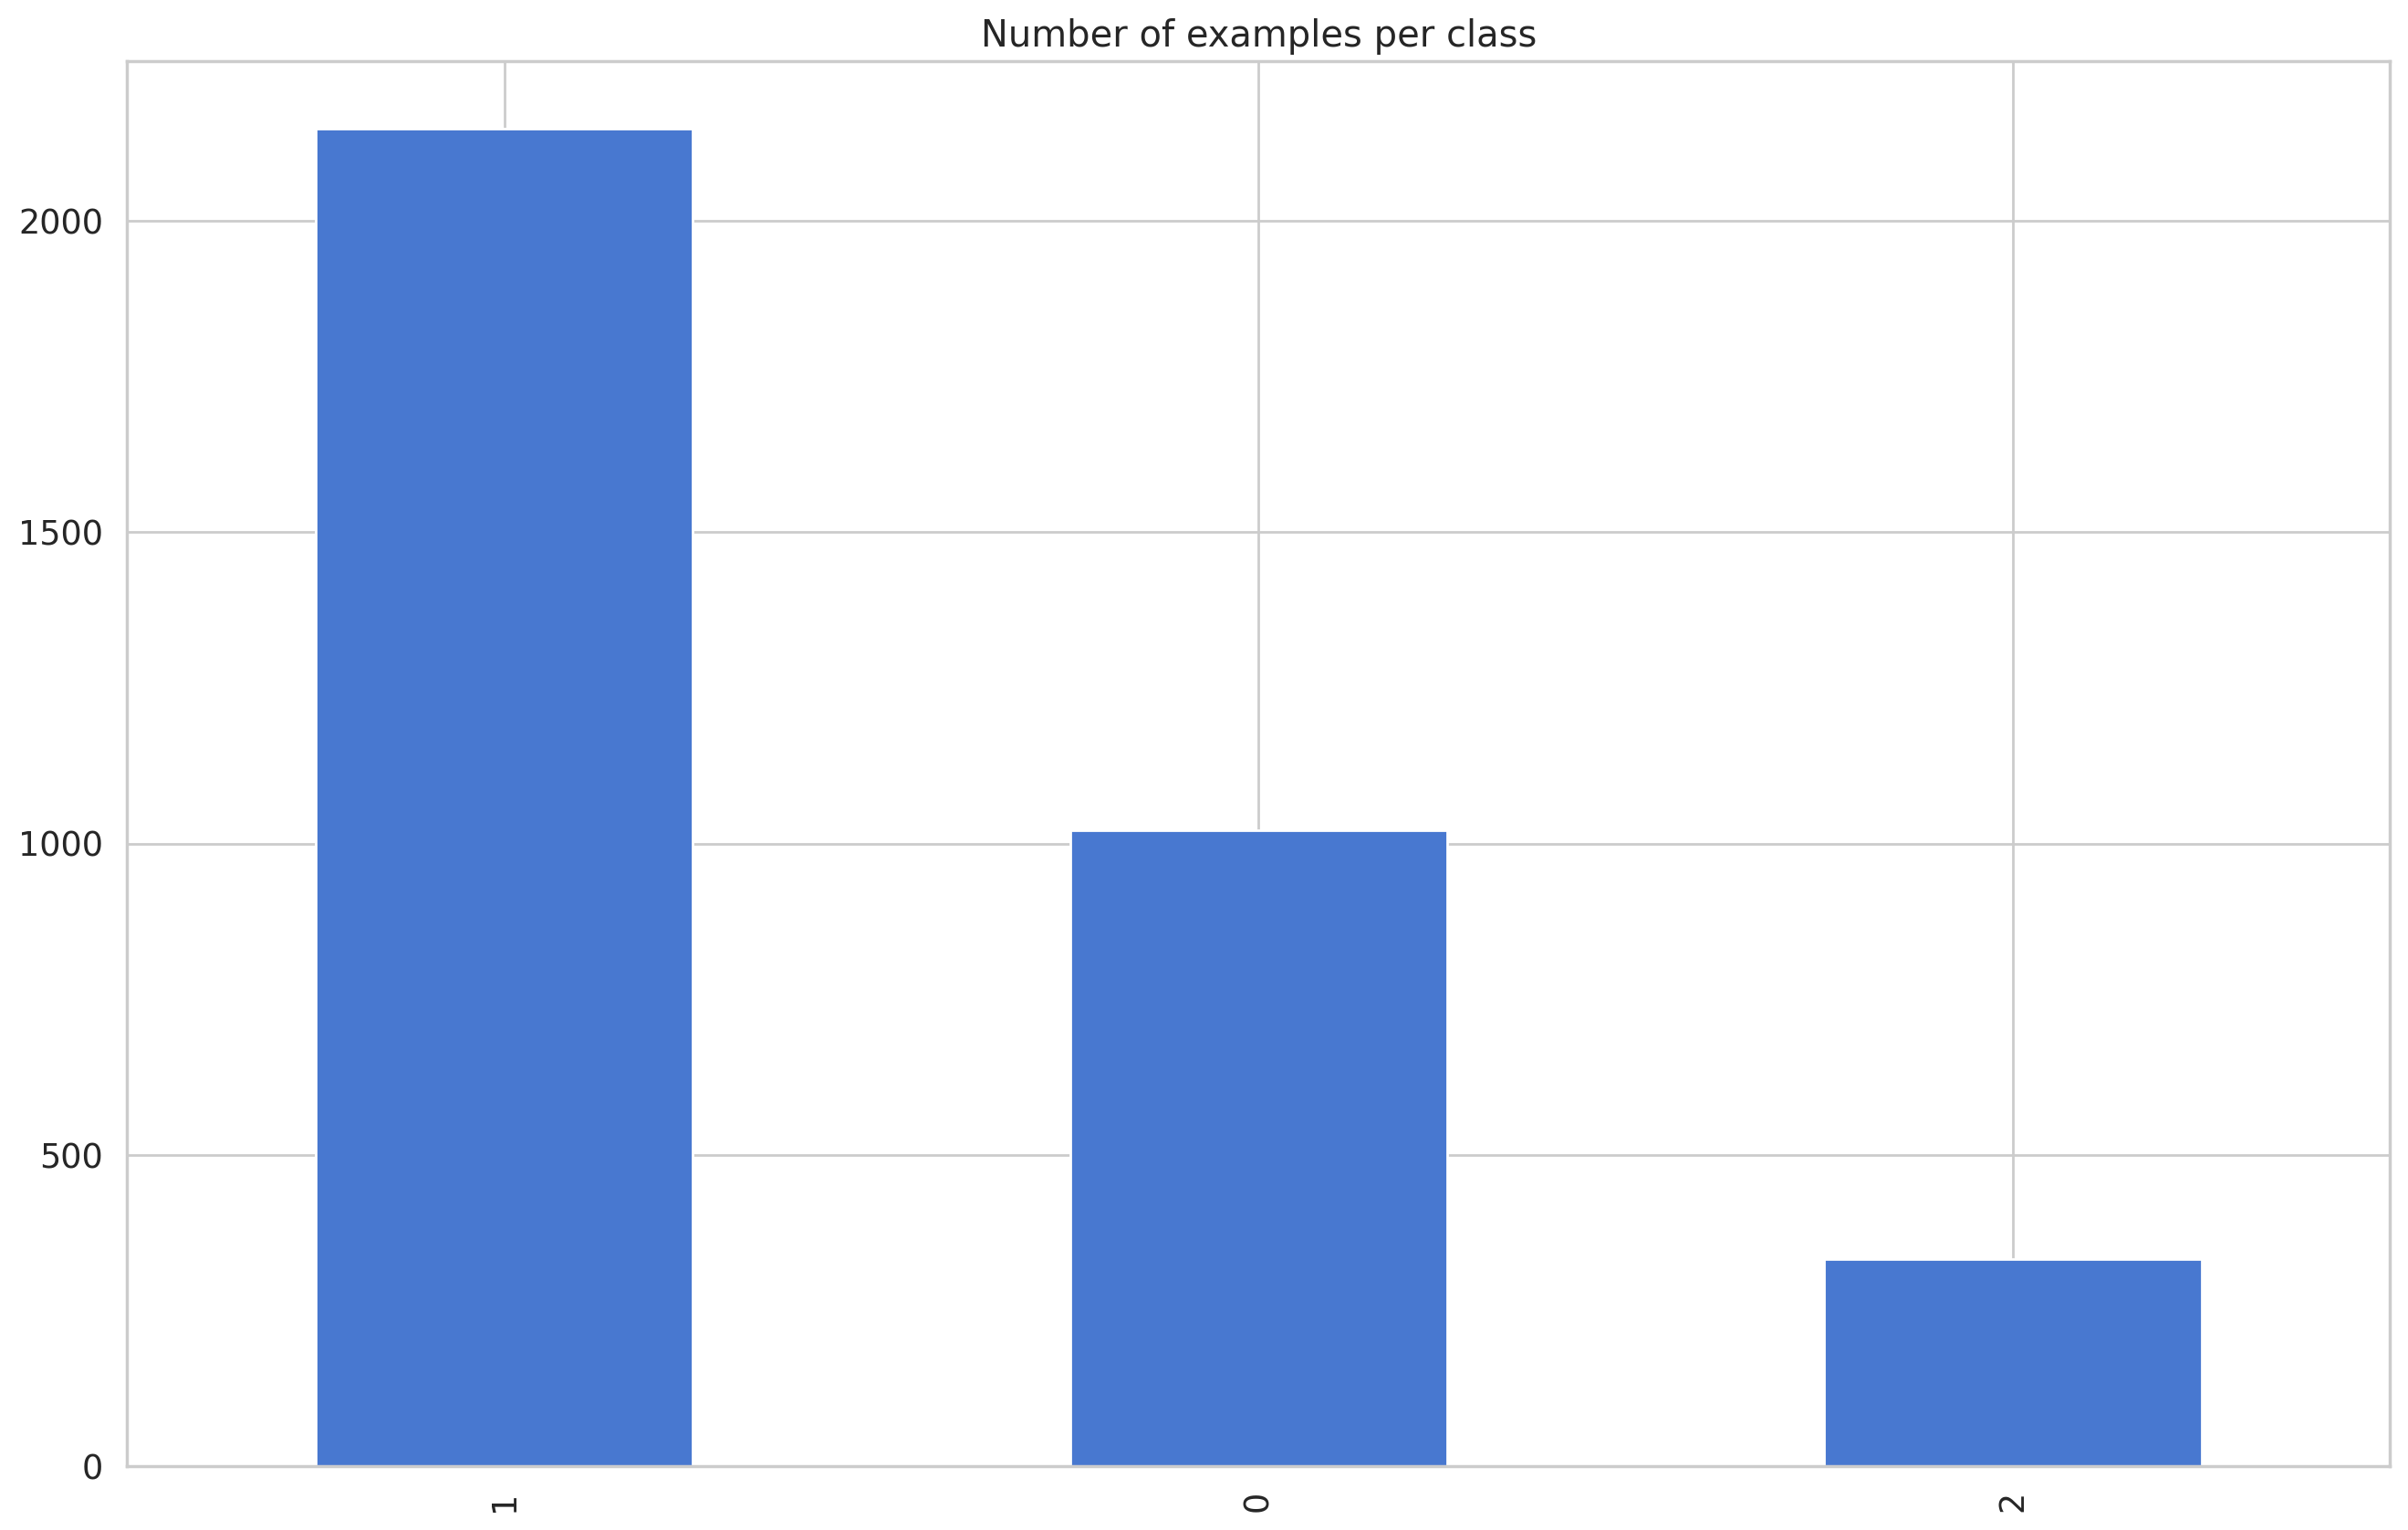

In [14]:
df['stance'].value_counts().sort_values(ascending=False).plot(kind="bar")
plt.title("Number of examples per class");

## Define specefic target

In [15]:
#Include only rows from specefic target
if Enable_TargetSpecefic == 'Yes':
  df= df[df['target'] == selectedTarget]
  test_df= test_df[test_df['target'] == selectedTarget]

print(df.shape)
print(test_df.shape)

(3502, 14)
(619, 14)


## Load data into Huggingface 

In [16]:
# load the dataset from pandas dataframe to Huggingface Dataset

tds = Dataset.from_pandas(df)
vds = Dataset.from_pandas(test_df)

loaded_datasets = DatasetDict()

loaded_datasets['train'] = tds
loaded_datasets['validation'] = vds

In [17]:
loaded_datasets

DatasetDict({
    train: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date'],
        num_rows: 3502
    })
    validation: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date'],
        num_rows: 619
    })
})

In [18]:
# Remove the extra column '__index_level_0__' when we convert from pandas to Huggingface
if '__index_level_0__' in loaded_datasets['train'].features:
    loaded_datasets = loaded_datasets.remove_columns(['__index_level_0__'])

## Preprocessing the tweets

### Regex preprocessing 

In [19]:
## Remove hashtags, URL, MENTION

def remove_hash_URL_MEN(text):
    #text = re.sub(r'#(\w+)','',text)
    text = re.sub(r'#',' ',text) #remove #
    text = re.sub(r'_',' ',text) #remove _
    text = re.sub(r'URL','',text)
    text = re.sub(r'MENTION','',text)
    return text

##  Remove punctuations

arabic_punctuations = '''`÷×؛<>()*&^%][ـ،/:"؟.,'{}~¦+|!”…“–ـ'''
english_punctuations = string.punctuation
punctuations_list = arabic_punctuations + english_punctuations

def remove_punctuations(text):
    translator = str.maketrans('', '', punctuations_list)
    return text.translate(translator)

##  Normalize_arabic

def normalize_arabic(text):
    text = re.sub("[إآ]", "ا", text)
    #text = re.sub("ى", "ي", text)
    #text = re.sub("ة", "ه", text)
    text = re.sub("گ", "ك", text)
    return text


## Remove_repeating_char

def remove_repeating_char(text):
    return re.sub(r'(.)\1+', r'\1', text)


# one4all preprocess

def processPost(tweet): 
    tweet['text']=remove_hash_URL_MEN(str(tweet['text']))

    #Replace @username with empty string
    tweet['text'] = re.sub('@[^\s]+', ' ', str(tweet['text']))
    
    #Convert www.* or https?://* to " "
    tweet['text'] = re.sub('((www\.[^\s]+)|(https?://[^\s]+))',' ',str(tweet['text']))
    
    #Replace #word with word
    #tweet['text'] = re.sub(r'#([^\s]+)', r'\1', str(tweet['text']))

    # remove punctuations
    #tweet['text']= remove_punctuations(str(tweet['text']))
    
    # normalize the tweet
    tweet['text']= normalize_arabic(str(tweet['text']))
    
    # remove repeated letters
    #tweet['text']=remove_repeating_char(str(tweet['text']))

    return tweet

In [20]:
# Regex preprocessing before tokenizing
loaded_datasets["train"] = loaded_datasets["train"].map(processPost)
loaded_datasets["validation"] = loaded_datasets["validation"].map(processPost)

Map:   0%|          | 0/3502 [00:00<?, ? examples/s]

Map:   0%|          | 0/619 [00:00<?, ? examples/s]

In [21]:
# Sanity check on the dataset after Regex processing
list(loaded_datasets["validation"]['text'][0:20])

##Q: some emojis is not included in the vocab

['الوضع صار بالسعوديه يفشل لا عاد فيه شركات صاحيه ولا مشاهير صاحين.  الوضع الحالي اقبح صور تسليع المرأه تحت مسمى تمكين المرأه!   مقاطعة شاهي خدير',
 '   الفساد الاداري انهك البلاد ومازلنا نعتمد على السندات اليدويه لتحصيل الايرادات لابد من التحول الالكتروني وبذالك نظمن جميع الايرادات',
 '-البي بي سي ١٠ دول اوروبية توقف تطعيم اوكسفورد..  -اطباء الكويت التطعيم بريء وامن..!!  تسويق وترقيع على حساب البشر غير معقول!!   لا للحظر  كورونا  التطعيم ',
 'منصة مدرستي بتسرع عملية التحول للتعليم الالكتروني. الان تقريبا جميع الطلاب معهم اجهزة اتمنى بعد انتهاء كورونا يسمحون لهم يجيبونها للمدرسة.',
 'انا مع تمكين المرأة اصلا ',
 '«بنك مصر» الأفضل في مجال التحول الرقمي وخدمات الصراف الالي والدفع الالكتروني ',
 ' نقل الاموال مكلفة وخطرة وطبع النقود بعد مكلف عشان كذا التحول للدفع الالكتروني. الكاش يضيع او ينسرق او يتلف',
 'من خلال تقديمي لدورات وورش عمل  التجارة الالكترونية  التسويق الألكتروني  التحول الرقمي هناك تنافس محموم بين  قوقل و  فيسبوك للاستحواذ على سوق الاعمال والأنشطة التجارية والتسويق مع وجود 

### AraBERT preprocessing


In [22]:
!git clone https://github.com/aub-mind/arabert/

fatal: destination path 'arabert' already exists and is not an empty directory.


In [23]:
!pip install emoji==1.6.1

In [24]:
from arabert.preprocess import ArabertPreprocessor

#https://github.com/aub-mind/arabert/blob/master/preprocess.py
# Default values of parameters:
#ArabertPreprocessor(model_name: str, remove_html_markup: bool=True, replace_urls_emails_mentions: bool=True, strip_tashkeel: bool=True, 
#                    strip_tatweel: bool=True, insert_white_spaces: bool=True, remove_non_digit_repetition: bool=True, keep_emojis: bool=None,
#                    replace_slash_with_dash: bool=None, map_hindi_numbers_to_arabic: bool=None, apply_farasa_segmentation: bool=None)

arabert_prep = ArabertPreprocessor(model_name=model_name) #keep_emojis will be automatically set to True in AraBERT-twitter.


In [25]:
sample_tweet = test_df.iloc[1]
sample_tweet.text

'   الفساد الإداري انهك البلاد ومازلنا نعتمد على السندات اليدويه لتحصيل الإيرادات لابد من التحول الإلكتروني وبذالك نظمن جميع الإيرادات'

In [26]:
sample_text = arabert_prep.preprocess(sample_tweet.text)
sample_text

'الفساد الإداري انهك البلاد ومازلنا نعتمد على السندات اليدويه لتحصيل الإيرادات لابد من التحول الإلكتروني وبذالك نظمن جميع الإيرادات'

In [27]:
# Convert dataset to dataframe for easy manipulation to apply arabert_prep.preprocess
df_pandas_train = pd.DataFrame(loaded_datasets['train'])
df_pandas_valid = pd.DataFrame(loaded_datasets['validation'])

# Apply arabert_prep.preprocess
df_pandas_train['text'] = df_pandas_train['text'].apply(lambda x: arabert_prep.preprocess(x))
df_pandas_valid['text'] = df_pandas_valid['text'].apply(lambda x: arabert_prep.preprocess(x))

# Recover to HF dataset
loaded_datasets['train']=loaded_datasets['train'].from_pandas(df_pandas_train)
loaded_datasets['validation']=loaded_datasets['validation'].from_pandas(df_pandas_valid)

In [28]:
# Sanity check on the dataset after arabert processing
list(loaded_datasets['train']['text'][0:20])

['عشان يلمع صورته ويعنني تمكين المرأة ويصير ترند والحكومة هي اكثر من تقمع المرأة اخر شيء كل الي فرحانين بالقرار ودارسين قانون متوظفين كاشير في مول راتبهم 3 الاف',
 'روح حلل محد يم تطعيم كورونا شف الحرم البارح مليونين بدون شرط تحصين 😅',
 "هذا ما يعرف ب ' فوبيا المرأة المتمكنة ' افة فكرية تغزو عقول بعض الرجال حيث انه اذ رأى تمكين للمرأة حتى ولو كان بسيطا فهو من المرجح بالطبع ربطه للموضوع مع - النسوية - وأتهام الفكرة بأكملها بالشيطنة والخبث .",
 'LEAP22 مؤتمر يجمع اشهر وابرز المؤثرين في المجال التقني ومن خلاله السعودية تستعرض قدرتها في التحول الرقمي اللي تشهدها كافة قطاعاتها 👌 🏼',
 'خصوصية البيانات وحمايتها في المنظمة مطلب ولكن لا ينبغي أن تكون ذريعة لسد الطريق امام التحول التقني لأننا نجهل كيف نحمي بياناتنا في هذا الفضاء التقني . بل أن عملية التحول الرقمي ليست خيارا نقبله أو نرفضه ونحن قطاع يتسم بالشفافية والمشاركة مع المجتمع وأصحاب المصلحة .',
 'فخورين بنساء الوطن 🇸 🇦 وكلنا فخر بتقدم تمكين المرأه يوم بعد يوم ؛ الله يديم حكومتنا ؛ ويحفظ بلادنا ويعزها 🤍 . .',
 'هه ماعليك زمن تمكين المرأة 

In [29]:
loaded_datasets

DatasetDict({
    train: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date'],
        num_rows: 3502
    })
    validation: Dataset({
        features: ['ID', 'text', 'target', 'stance', 'stance:confidence', 'against_reason', 'favor_reason', 'none_reason', 'sarcasm', 'sarcasm:confidence', 'sentiment', 'sentiment:confidence', 'datetime', 'Date'],
        num_rows: 619
    })
})

# Building The Multi-Task Dataset

1. Define the tokenizer
2. Build and tokenize the stance_dataset
3. Build and tokenize the sentiment_dataset
4. Build and tokenize the sarcasm_dataset
5. Merge all datasets

In [30]:
## Parameters
max_length= 128 
seednum= 42

In [31]:
## Define the tokenizer        
tokenizer = AutoTokenizer.from_pretrained(model_name) #,add_prefix_space=True)

In [32]:
# A class for the task, inherit from dataclass where we specifie id, name ,type,num_labels
@dataclass
class Task:
    id: int
    name: str
    type: str
    num_labels: int

### Stance dataset

In [33]:
def load_stance_dataset():
    
    task_name = 'stance'
    num_labels =3  # {'None': 2, 'Favor': 1, 'Against': 0}
    task_id=1 # id of the task

    def tokenize_text(examples):

        result = tokenizer(examples['text'], examples['target'],
              padding='max_length',max_length=max_length, truncation=True,
        )
        result["task_ids"] = [task_id] * len(examples["label"])

        return result

    raw_datasets = loaded_datasets

    ## We need to rename the column to merge all the datasets later
    raw_datasets = raw_datasets.rename_column('stance', 'label') # rename column 


    # removing the none class
    # change: num_labels =2 
    #############################################
    '''
    df_pandas_train = pd.DataFrame(raw_datasets['train'])# convert dataset to dataframe for easy manipulation
    df_pandas_valid = pd.DataFrame(raw_datasets['validation'])

    df_pandas_train=df_pandas_train[df_pandas_train['label']!=0]# remove third class (None,label=0)
    df_pandas_valid=df_pandas_valid[df_pandas_valid['label']!=0]

    # mapping to start from zero
    mapping_stance = {1: 0, 2: 1}
    df_pandas_train['label'] = df_pandas_train['label'].apply(lambda x: mapping_stance[x])
    df_pandas_valid['label'] = df_pandas_valid['label'].apply(lambda x: mapping_stance[x])
    
    raw_datasets['train']=raw_datasets['train'].from_pandas(df_pandas_train)# recover to dataset
    raw_datasets['validation']=raw_datasets['validation'].from_pandas(df_pandas_valid)

    raw_datasets = raw_datasets.remove_columns(['__index_level_0__'])# this index is added by pandas when convertint to dataset (need to be removed)
    '''
    #############################################

    # PreProcessing
    #raw_datasets["train"] = raw_datasets["train"].map(processPost)# preprocessing before tokenizing

    # Tokonizing , and remove columns
    col_to_remove=['ID','text','target','stance:confidence','against_reason','favor_reason','none_reason','sarcasm','sarcasm:confidence','sentiment','sentiment:confidence','datetime','Date']
    
    train_dataset = raw_datasets["train"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)
    validation_dataset = raw_datasets["validation"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)

    # Add task field
    task_info = Task(id=task_id, name=task_name, num_labels=num_labels, type="seq_classification" )
    
    return train_dataset,validation_dataset,task_info



In [34]:
load_stance_dataset()

Map:   0%|          | 0/3502 [00:00<?, ? examples/s]

Map:   0%|          | 0/619 [00:00<?, ? examples/s]

(Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 3502
 }),
 Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 619
 }),
 Task(id=1, name='stance', type='seq_classification', num_labels=3))

### Sentiment dataset

In [35]:
def load_sentiment_dataset():
    
    task_name = 'sentiment'
    num_labels =3 # {'Neutral': 2, 'Positive': 1, 'Negative': 0}
    task_id=2
  
    def tokenize_text(examples):

        result = tokenizer(examples['text'],
              padding='max_length',max_length=max_length, truncation=True,
        )
        result["task_ids"] = [task_id] * len(examples["label"])

        return result

    raw_datasets = loaded_datasets
    raw_datasets = raw_datasets .rename_column('sentiment', 'label')# rename column

    # PreProcessing
    #raw_datasets["train"] = raw_datasets["train"].map(processPost)# preprocessing before tokenizing

    # Tokonizing , and remove columns
    col_to_remove=['ID','text','target','stance','stance:confidence','against_reason','favor_reason','none_reason','sarcasm','sarcasm:confidence','sentiment:confidence','datetime','Date']
    
    train_dataset = raw_datasets["train"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)
    validation_dataset = raw_datasets["validation"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)

    # Add task field
    task_info = Task(id=task_id, name=task_name, num_labels=num_labels, type="seq_classification" )

    return train_dataset,validation_dataset,task_info


In [36]:
load_sentiment_dataset()

Map:   0%|          | 0/3502 [00:00<?, ? examples/s]

Map:   0%|          | 0/619 [00:00<?, ? examples/s]

(Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 3502
 }),
 Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 619
 }),
 Task(id=2, name='sentiment', type='seq_classification', num_labels=3))

### Sarcasm dataset

In [37]:
def load_sarcasm_dataset():
    
    task_name = 'sarcasm'
    num_labels =2 # {"Yes": 1, "No": 0}
    task_id=3

    def tokenize_text(examples):

        result = tokenizer(examples['text'],
              padding='max_length',max_length=max_length, truncation=True,
        )
        result["task_ids"] = [task_id] * len(examples["label"])

        return result


    raw_datasets = loaded_datasets
    raw_datasets = raw_datasets .rename_column('sarcasm', 'label')# rename column

    # PreProcessing
    #raw_datasets["train"] = raw_datasets["train"].map(processPost)# preprocessing before tokenizing

    # Tokonizing , and remove columns
    col_to_remove=['ID','text','target','stance','stance:confidence','against_reason','favor_reason','none_reason','sarcasm:confidence','sentiment','sentiment:confidence','datetime','Date']
    
    train_dataset = raw_datasets["train"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)
    validation_dataset = raw_datasets["validation"].map(tokenize_text,batched=True,load_from_cache_file=True,remove_columns=col_to_remove)

    # Add task field
    task_info = Task(id=task_id, name=task_name, num_labels=num_labels, type="seq_classification" )
    
    return train_dataset,validation_dataset,task_info

In [38]:
load_sarcasm_dataset()

Map:   0%|          | 0/3502 [00:00<?, ? examples/s]

Map:   0%|          | 0/619 [00:00<?, ? examples/s]

(Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 3502
 }),
 Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
     num_rows: 619
 }),
 Task(id=3, name='sarcasm', type='seq_classification', num_labels=2))

### Merging the 3 datasets

In [39]:
def load_datasets():
    # load three datasets and merge it to have only one dataset 
    (
        seq_classification_train_dataset1,
        seq_classification_validation_dataset1,
        seq_classification_task1,
    ) = load_stance_dataset()

    (
        seq_classification_train_dataset2,
        seq_classification_validation_dataset2,
        seq_classification_task2,
    ) = load_sentiment_dataset()

    (
        seq_classification_train_dataset3,
        seq_classification_validation_dataset3,
        seq_classification_task3,
    ) = load_sarcasm_dataset()
 

    # Merge train datasets
    train_dataset_df = seq_classification_train_dataset1.to_pandas().append(
        seq_classification_train_dataset2.to_pandas().append(
            seq_classification_train_dataset3.to_pandas()
            )
    )

    train_dataset = datasets.Dataset.from_pandas(train_dataset_df)
    train_dataset=train_dataset.shuffle(seed=seednum)

    # Append validation datasets
    validation_dataset = [
        seq_classification_validation_dataset1,
        seq_classification_validation_dataset2,
        seq_classification_validation_dataset3
    ]

    dataset = datasets.DatasetDict(
        {"train": train_dataset, "validation": validation_dataset}
    )
    
    tasks = [seq_classification_task1, seq_classification_task2, seq_classification_task3]

    return tasks, dataset

# Multi-Task Model

1. Create attention heads
2. Define the encoder
3. Build multi-task model

In [40]:
def generate_parameter(task):
    
    if Weight == 'SW':
        if task == "stance":
            w = 0.6
        elif task == "sentiment":
            w = 0.3
        elif task == "sarcasm":
            w = 0.1
            
    elif Weight == 'W3':
        if task == "stance":
            w = 0.6
        elif task == "sentiment":
            w = 0.3
        elif task == "sarcasm":
            w = 0.1
        w = nn.Parameter(torch.tensor(1,dtype=torch.float), requires_grad=True)
        
    return w 

In [41]:
#w = nn.Parameter(torch.tensor(1,dtype=torch.float), requires_grad=True)
#w

In [42]:
#w = nn.Parameter(torch.rand(1,dtype=torch.float), requires_grad=True)
#w

### Stance Head

In [43]:
class SequenceClassificationHeadStance(nn.Module):
    
    def __init__(self, hidden_size, num_labels, dropout_p=0.1):
        super().__init__()
        self.num_labels = num_labels
        self.dropout = nn.Dropout(dropout_p)
        self.classifier = nn.Linear(hidden_size, num_labels)
        ### W ###
        self.w = generate_parameter("stance")

        self._init_weights()

    #def forward(self, sequence_output, pooled_output, labels=None, **kwargs):
    def forward(self,pooled_output, labels=None, **kwargs):
        pooled_output = self.dropout(pooled_output)
        logits = self.classifier(pooled_output) #logits is the values of the predections (not between 0 and 1)

        loss = None
 
        if labels is not None:

            loss_fct = nn.CrossEntropyLoss()

            print()
            loss = self.w*loss_fct(
                logits.view(-1, self.num_labels), labels.long().view(-1)
            )
            logged_loss = loss / self.w
            wandb.log({'Stance_loss': logged_loss})
             
        return logits, loss
    
    def get_weight(self):
        return self.w

    def _init_weights(self):
        self.classifier.weight.data.normal_(mean=0.0, std=0.02)
        if self.classifier.bias is not None:
            self.classifier.bias.data.zero_()
  

### Sentiment Head

In [44]:
class SequenceClassificationHeadSentiment(nn.Module):
    
    def __init__(self, hidden_size, num_labels, dropout_p=0.1):
        super().__init__()
        self.num_labels = num_labels
        self.dropout = nn.Dropout(dropout_p)
        self.classifier = nn.Linear(hidden_size, num_labels)
        ### W ###
        self.w = generate_parameter("sentiment")

        self._init_weights()

    #def forward(self, sequence_output, pooled_output, labels=None, **kwargs):
    def forward(self,pooled_output, labels=None, **kwargs):
        pooled_output = self.dropout(pooled_output)
        logits = self.classifier(pooled_output)

        loss = None
        if labels is not None:
          
          loss_fct = nn.CrossEntropyLoss()
          loss = self.w*loss_fct(
                logits.view(-1, self.num_labels), labels.long().view(-1)
            )
          logged_loss = loss / self.w
          wandb.log({'Sentiment_loss': logged_loss})

        return logits, loss

    def _init_weights(self):
        self.classifier.weight.data.normal_(mean=0.0, std=0.02)
        if self.classifier.bias is not None:
            self.classifier.bias.data.zero_()
            

### Sarcasm Head

In [45]:
class SequenceClassificationHeadSarcasm(nn.Module):

    def __init__(self, hidden_size, num_labels, dropout_p=0.1):
        super().__init__()
        self.num_labels = num_labels
        self.dropout = nn.Dropout(dropout_p)
        self.classifier = nn.Linear(hidden_size, num_labels)
        ### W ###
        self.w = generate_parameter("sarcasm")

        self._init_weights()

    #def forward(self, sequence_output, pooled_output, labels=None, **kwargs):
    def forward(self,pooled_output, labels=None, **kwargs):
        pooled_output = self.dropout(pooled_output)
        logits = self.classifier(pooled_output)

        loss = None
        if labels is not None:

            loss_fct = nn.CrossEntropyLoss()
            loss = self.w*loss_fct(
                logits.view(-1, self.num_labels), labels.long().view(-1)
            )
            logged_loss = loss / self.w
            wandb.log({'Sarcasm_loss': logged_loss})

        return logits, loss

    def _init_weights(self):
        self.classifier.weight.data.normal_(mean=0.0, std=0.02)
        if self.classifier.bias is not None:
            self.classifier.bias.data.zero_()
            

### Multi-task class

In [46]:
class MultiTaskModel(nn.Module):

    def __init__(self, model_name, tasks: List):
        super().__init__()

        ## Define the encoder:
        self.encoder = AutoModel.from_pretrained(model_name)

        self.output_heads = nn.ModuleDict()
        for task in tasks:
            decoder = self._create_output_head(self.encoder.config.hidden_size, task)
            # ModuleDict requires keys to be strings
            self.output_heads[str(task.id)] = decoder

    @staticmethod
    def _create_output_head(encoder_hidden_size: int, task):
        if task.name == "stance":
            return SequenceClassificationHeadStance(encoder_hidden_size, task.num_labels)
        elif task.name == "sarcasm":
            return SequenceClassificationHeadSarcasm(encoder_hidden_size, task.num_labels)
        elif task.name == "sentiment":
            return SequenceClassificationHeadSentiment(encoder_hidden_size, task.num_labels)
        else:
            raise NotImplementedError()
   
    def forward(
        self,
        input_ids=None,
        attention_mask=None,
        token_type_ids=None,
        position_ids=None,
        head_mask=None,
        inputs_embeds=None,
        labels=None,
        task_ids=None,
        **kwargs,
    ):

        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            position_ids=position_ids,
            head_mask=head_mask,
            inputs_embeds=inputs_embeds,
        )

        #sequence_output, pooled_output = outputs[:2]# sequence_output  are the hidden representations of all tokens 
        pooled_output = outputs[1]
        # pooler layer takes the final hidden representation of the [CLS] token (this is a vector of size 768),
        #then applies a linear layer and tanh to it
        # pooled_output=[batch_size, 768]
        
        unique_task_ids_list = torch.unique(task_ids).tolist()# unique_task_ids_list=[1,2,3] ,task_ids=[1,2,3,1,1,2,1]

        loss_list = []
        logits = None
        for unique_task_id in unique_task_ids_list:
            #task_id_filter is used to filter only the task in hand from the batch for example 
            ## ask_id_filter for task=3 ,task_id_filter=tensor([False, False, True, False, False, False, False])

            task_id_filter = task_ids == unique_task_id 
            logits, task_loss = self.output_heads[str(unique_task_id)].forward(
                #sequence_output[task_id_filter],# size of (batch_size, hidden_size) for our case (32,768)
                pooled_output[task_id_filter],# size of (batch_size, hidden_size) for our case (32,768)
                labels=None if labels is None else labels[task_id_filter],
                attention_mask=attention_mask[task_id_filter],
            )

            if labels is not None:
                loss_list.append(task_loss)

        # logits are only used for eval. and in case of eval the batch is not multi task
        # For training only the loss is used
        # outputs[2:] is the same as outputs[1] --> try it first
        outputs = (logits, outputs[2:])

        if loss_list:
            ### W1 ###
            loss = torch.stack(loss_list)
            #outputs = (loss.sum(),) + outputs
            outputs = (loss.mean(),) + outputs

        return outputs


# Training

### Loading for training

In [47]:
# Import for trainer

from transformers import Trainer, DataCollatorWithPadding
from transformers import (
    AutoConfig,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EvalPrediction,
    HfArgumentParser,
    PretrainedConfig,
    Trainer,
    TrainingArguments,
    default_data_collator,
    set_seed,
)
 

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


In [48]:
# Load the multi task dataset
tasks, dataset=load_datasets()

# Build the multi task model
model=MultiTaskModel(model_name,tasks)

## pad_to_multiple_of=8 --> this just for the GPU during training
data_collator = DataCollatorWithPadding(
                        tokenizer, pad_to_multiple_of=8
                    )

# Load the train dataset
train_dataset = dataset["train"]

# Load the validation dataset
validstance, validsarcasm, validsentiment = dataset['validation']
#validstance,validsentiment=dataset['validation']


Map:   0%|          | 0/3502 [00:00<?, ? examples/s]

Map:   0%|          | 0/619 [00:00<?, ? examples/s]

Map:   0%|          | 0/3502 [00:00<?, ? examples/s]

Map:   0%|          | 0/619 [00:00<?, ? examples/s]

Map:   0%|          | 0/3502 [00:00<?, ? examples/s]

Map:   0%|          | 0/619 [00:00<?, ? examples/s]

/tmp/ipykernel_519417/3348369871.py:24: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  seq_classification_train_dataset2.to_pandas().append(
/tmp/ipykernel_519417/3348369871.py:23: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  train_dataset_df = seq_classification_train_dataset1.to_pandas().append(
Some weights of the model checkpoint at aubmindlab/bert-base-arabertv02-twitter were not used when initializing BertModel: ['cls.predictions.transform.dense.weight', 'cls.predictions.decoder.weight', 'cls.predictions.decoder.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.bias', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.LayerNorm.bias']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture 

In [49]:
# We should have 1 merged dataset and 3 validation sets (one for each task)
dataset

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids', '__index_level_0__'],
        num_rows: 10506
    })
    validation: [Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 619
    }), Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 619
    }), Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids'],
        num_rows: 619
    })]
})

In [50]:
train_dataset

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask', 'task_ids', '__index_level_0__'],
    num_rows: 10506
})

In [51]:
dataset['train'] = dataset['train'].remove_columns(['__index_level_0__'])

In [52]:
train_dataset = train_dataset.remove_columns(['__index_level_0__'])

### Define metrics

In [53]:
def compute_metrics(p: EvalPrediction):
    preds = np.argmax(p.predictions[0],axis=1)
    target=p.label_ids
    #print(classification_report(target,preds))
 
    return {
            "precision": round(precision_score(target, preds, average='macro'),4),
            "recall": round(recall_score(target, preds, average='macro'),4),
            "macro_f1": round(f1_score(target, preds, average='macro'),4),
            "accuracy": round(accuracy_score(target, preds),4),
        }

### Logging to WANDB

In [54]:
#!pip install wandb

In [55]:
import wandb

In [56]:
wandb.login()

# API key:
# <removed>
# old: <removed>

Failed to detect the name of this notebook, you can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


wandb: Currently logged in as: nora_sa. Use `wandb login --relogin` to force relogin


True

In [57]:
import wandb

wandb.init(project="Multi_task", entity="nora_sa")

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


In [58]:
#%env "WANDB_NOTEBOOK_NAME" "Multi_Task"

### Define Trainer

In [59]:
def set_seed(seed=42):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)
  torch.backends.cudnn.deterministic=True
  torch.backends.cudnn.benchmark = False

In [60]:
## NEW
training_args=transformers.TrainingArguments(
        output_dir="./models",
        overwrite_output_dir=True,
        learning_rate=2e-5, #1e-5
        adam_epsilon = 1e-8,
        #fp16 = True, # set this to True when using V100 or T4 GPU
        do_train=True,
        do_eval=True,
        num_train_epochs=20,
        per_device_train_batch_size = 4, #8, # up to 64 on 16GB with max len of 128
        #per_device_eval_batch_size = 1, #default is 8
        gradient_accumulation_steps = 8, #4, # use this to scale batch size without needing more memory 
        #batch_size will be 32 (per_device_train_batch_size*gradient_accumulation_steps = 4*8)  
        #warmup_ratio = 0,
        #save_steps=500,
        logging_steps = 100, #default logging_steps is set to 500 steps, so no loss is reported before 500 steps (decrease it to solve No log loss issue)
        evaluation_strategy = 'epoch', #'steps', #
        save_strategy = 'epoch',
        load_best_model_at_end = True, # this allows to automatically get the best model at the end based on whatever metric we want
        metric_for_best_model = 'macro_f1',
        greater_is_better = True,
        seed = 42,
        report_to="wandb",
        run_name = Ex_name # to log the experiment in wandb
    )

set_seed(training_args.seed)


#### Some calculations:

**total_train_batch_size** = args.train_batch_size * args.gradient_accumulation_steps * args.world_size

--> total_train_batch_size = 16 * 2 * 1 = 32

-------------

**num_update_steps_per_epoch** = len(train_dataloader) / args.gradient_accumulation_steps

**len(train_dataloader)** = #batches = #samples/ args.train_batch_size = 10506 / 16 = 656

--> num_update_steps_per_epoch = 656 / 2 = 328

-------

**max_steps** = math.ceil(args.num_train_epochs * num_update_steps_per_epoch)

--> max_steps = math.ceil(20 * 328) = 6560

-------


In [61]:
## NEW
trainer = Trainer(
    model = model,
    args = training_args,
    train_dataset = train_dataset,
    eval_dataset=validstance,
    compute_metrics=compute_metrics,
    tokenizer=tokenizer,
    data_collator=data_collator,
)

In [62]:
trainer.train()


/home/nora_alturayeif/.conda/envs/stance/lib/python3.9/site-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 10506
  Num Epochs = 20
  Instantaneous batch size per device = 4
  Total train batch size (w. parallel, distributed & accumulation) = 32
  Gradient Accumulation steps = 8
  Total optimization steps = 6560
  Number of trainable parameters = 135199496
Automatic Weights & Biases logging enabled, to disable set os.environ["WANDB_DISABLED"] = "true"
You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Epoch,Training Loss,Validation Loss


***** Running Evaluation *****
  Num examples = 619
  Batch size = 8
  Num examples = 619
  Batch size = 8


Saving model checkpoint to ./models/checkpoint-328
Trainer.model is not a `PreTrainedModel`, only saving its state dict.
tokenizer config file saved in ./models/checkpoint-328/tokenizer_config.json
Special tokens file saved in ./models/checkpoint-328/special_tokens_map.json


Saving model checkpoint to ./models/checkpoint-656
Trainer.model is not a `PreTrainedModel`, only saving its state dict.
tokenizer config file saved in ./models/checkpoint-656/tokenizer_config.json
Special tokens file saved in ./models/checkpoint-656/special_tokens_map.json


Saving model checkpoint to ./models/checkpoint-984
Trainer.model is not a `PreTrainedModel`, only saving its state dict.
tokenizer config file saved in ./models/checkpoint-984/tokenizer_config.json
Special tokens file saved in ./models/checkpoint-984/special_tokens_map.json


... (5 outputs left out)

***** Running Evaluation *****
  Num examples = 619
  Batch size = 8
  Num examples = 619
  Batch size = 8


Saving model checkpoint to ./models/checkpoint-6232
Trainer.model is not a `PreTrainedModel`, only saving its state dict.
tokenizer config file saved in ./models/checkpoint-6232/tokenizer_config.json
Special tokens file saved in ./models/checkpoint-6232/special_tokens_map.json


Saving model checkpoint to ./models/checkpoint-6560
Trainer.model is not a `PreTrainedModel`, only saving its state dict.
tokenizer config file saved in ./models/checkpoint-6560/tokenizer_config.json
Special tokens file saved in ./models/checkpoint-6560/special_tokens_map.json


Training completed. Do not forget to share your model on huggingface.co/models =)


Loading best model from ./models/checkpoint-1968 (score: 0.7044).
Could not locate the best model at ./models/checkpoint-1968/pytorch_model.bin, if you are running a distributed training on multiple nodes, you should activate `--save_on_each_node`.


ValueError: 'models/checkpoint-1968' is not in list

# Evaluation

In [ ]:
# Get predictions
preds_target = trainer.predict(validstance)

print(compute_metrics(preds_target))

***** Running Prediction *****
  Num examples = 206
  Batch size = 8



























{'precision': 0.6663, 'recall': 0.6544, 'macro_f1': 0.6568, 'accuracy': 0.7621}


In [ ]:
pt=preds_target

preds = np.argmax(pt.predictions[0],axis=1)
target=pt.label_ids

#print(preds)
#print(target)

report_test = classification_report(target, preds, zero_division=0, digits=4)
print(report_test)

              precision    recall  f1-score   support

           0     0.7619    0.8889    0.8205        90
           1     0.8734    0.7667    0.8166        90
           2     0.3636    0.3077    0.3333        26

    accuracy                         0.7621       206
   macro avg     0.6663    0.6544    0.6568       206
weighted avg     0.7604    0.7621    0.7573       206



In [ ]:
report_test = classification_report(target, preds, zero_division=0, digits=4, output_dict=True)
report_df = pd.DataFrame(report_test).transpose()

In [ ]:
tbl = wandb.Table(dataframe=report_df)

wandb.log({Ex_name: tbl})

In [ ]:
cf_matrix = confusion_matrix(target, preds)
print(cf_matrix)

[[80  3  7]
 [14 69  7]
 [11  7  8]]


In [ ]:
class_names = ['Against','Favor','None']

(3, 3)


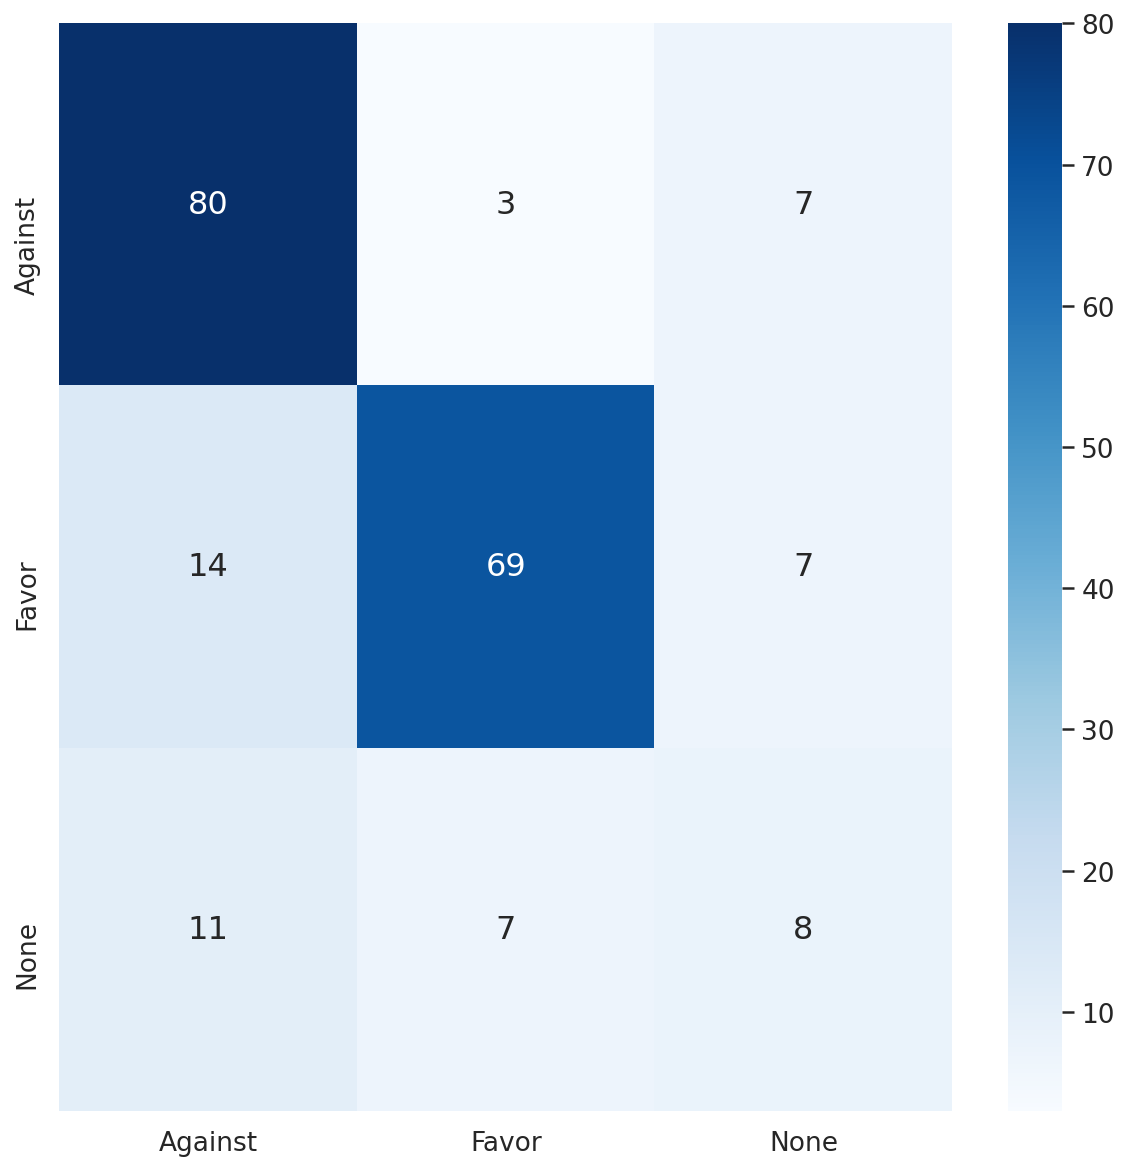

In [ ]:
#visualize confusion matrix

cm_df = np.asarray(cf_matrix).reshape(3,3)

print(cm_df.shape)
plt.figure(figsize = (10,10))
sns.heatmap(cm_df, annot=True, fmt='', cmap='Blues',annot_kws={"size": 16}, xticklabels=class_names, yticklabels=class_names)
plt.show()

# Write results

In [ ]:
ex_report_test = classification_report(target, preds, target_names=class_names, zero_division=0, digits=4, output_dict=True)

print(ex_report_test)

df_report_test = pd.DataFrame(ex_report_test).transpose()

df_report_test.to_csv(Ex_name+'_Test_report.csv', sep=',')

{'Against': {'precision': 0.7619047619047619, 'recall': 0.8888888888888888, 'f1-score': 0.8205128205128205, 'support': 90}, 'Favor': {'precision': 0.8734177215189873, 'recall': 0.7666666666666667, 'f1-score': 0.8165680473372781, 'support': 90}, 'None': {'precision': 0.36363636363636365, 'recall': 0.3076923076923077, 'f1-score': 0.33333333333333337, 'support': 26}, 'accuracy': 0.7621359223300971, 'macro avg': {'precision': 0.6663196156867043, 'recall': 0.6544159544159543, 'f1-score': 0.6568047337278107, 'support': 206}, 'weighted avg': {'precision': 0.7603571308868102, 'recall': 0.7621359223300971, 'f1-score': 0.7573007027824054, 'support': 206}}


# Save and Load the model

In [ ]:
#Save

# Define the file path where you want to save the trained model
model_path = "/home/nora_alturayeif/STANCE/Multitask/models/SW_MTL/model.pth"

# Save the trained model state dictionary to the file
torch.save(model.state_dict(), model_path)